## Funding at six exchanges

The funding of Bitcoin's and Ether's perpetuals at the six exchanges over the 90 days before
the run, the history OKX keeps. Five venues settle funding at fixed times, every eight hours
or every hour, and Kraken accrues it continuously; `funding_per_hour` puts them all on one
scale. The window ends at the run, so its numbers move from one run to the next.

In [1]:
import exchange_router
import exchange_router.funding
import matplotlib.colors
import matplotlib.pyplot
import pandas

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"exchange-router {exchange_router.__version__}")

exchange-router 3.3.0


### The events

A market handle binds a venue, a market and a symbol once. Its mark price gives the funding
cycle, from which the events of 90 days and one more are asked for, `start` naming the
newest; each series is then cut to the window.

In [2]:
SYMBOLS = {"BTC": {"binance": "BTCUSDT", "bybit": "BTCUSDT", "okx": "BTCUSDT",
                   "kraken": "XBTUSD", "kucoin": "XBTUSDT", "hyperliquid": "BTCUSDC"},
           "ETH": {"binance": "ETHUSDT", "bybit": "ETHUSDT", "okx": "ETHUSDT",
                   "kraken": "ETHUSD", "kucoin": "ETHUSDT", "hyperliquid": "ETHUSDC"}}

end   = pandas.Timestamp.now(tz="UTC").floor(freq="D")
start = end - pandas.Timedelta(days=90)

events = {}
with exchange_router.Router.local(exchanges=list(SYMBOLS["BTC"])) as router:
    for coin, symbols in SYMBOLS.items():
        for exchange, symbol in symbols.items():
            market = router.market(exchange=exchange, market_type="linear", symbol=symbol)
            cycle  = market.mark_price()["funding_cycle_ms"]
            frame  = market.funding_rate(limit=90 * 86_400_000 // cycle + 1,
                                         start=int(end.timestamp() * 1_000))
            events[coin, exchange] = frame[(frame.index >= start) & (frame.index < end)]

print(f"{start:%Y-%m-%d} to {end:%Y-%m-%d}")

2026-08-10 to 2026-11-08


### Discrete and continuous

Each series as it came: the kind of funding, how far apart its events are, and its mean rate
per hour.

In [3]:
pandas.DataFrame([{"kind": frame.attrs["funding_kind"],
                   "every hours": frame["cycle_ms"].median() / 3_600_000,
                   "events": len(frame), "first": frame.index[0], "last": frame.index[-1],
                   "mean per hour, bps": frame["funding_per_hour"].mean() * 10_000}
                  for frame in events.values()],
                 index=pandas.MultiIndex.from_tuples(tuples=list(events))).round(decimals=3)

kind  every hours  events  \
BTC binance        discrete          8.0     270   
    bybit          discrete          8.0     270   
    okx            discrete          8.0     270   
    kraken       continuous          1.0    2159   
    kucoin         discrete          8.0     270   
    hyperliquid    discrete          1.0    2160   
ETH binance        discrete          8.0     270   
    bybit          discrete          8.0     270   
    okx            discrete          8.0     270   
    kraken       continuous          1.0    2159   
    kucoin         discrete          8.0     270   
    hyperliquid    discrete          1.0    2160   

                                           first  \
BTC binance     2026-08-10 00:00:00.001000+00:00   
    bybit              2026-08-10 00:00:00+00:00   
    okx                2026-08-10 00:00:00+00:00   
    kraken             2026-08-10 00:00:00+00:00   
    kucoin             2026-08-10 00:00:00+00:00   
    hyperliquid 2026-08-10 00:00:00.029000+00:00   
ETH binance     2026-08-10 00:00:00.001000+00:00   
    bybit              2026-08-10 00:00:00+00:00   
    okx                2026-08-10 00:00:00+00:00   
    kraken             2026-08-10 00:00:00+00:00   
    kucoin             2026-08-10 00:00:00+00:00   
    hyperliquid 2026-08-10 00:00:00.029000+00:00   

                                            last  mean per hour, bps  
BTC binance            2026-11-07 16:00:00+00:00               0.070  
    bybit              2026-11-07 16:00:00+00:00               0.060  
    okx                2026-11-07 16:00:00+00:00               0.072  
    kraken             2026-11-07 23:00:00+00:00               0.094  
    kucoin             2026-11-07 16:00:00+00:00               0.064  
    hyperliquid 2026-11-07 23:00:00.002000+00:00               0.104  
ETH binance            2026-11-07 16:00:00+00:00               0.055  
    bybit              2026-11-07 16:00:00+00:00               0.049  
    okx                2026-11-07 16:00:00+00:00               0.060  
    kraken             2026-11-07 23:00:00+00:00               0.090  
    kucoin             2026-11-07 16:00:00+00:00               0.059  
    hyperliquid 2026-11-07 23:00:00.002000+00:00               0.101

### By day, annualised

Each day's mean rate per hour over its events, times the hours of a year: what a long paid
that day as a yearly rate, a negative one what it received.

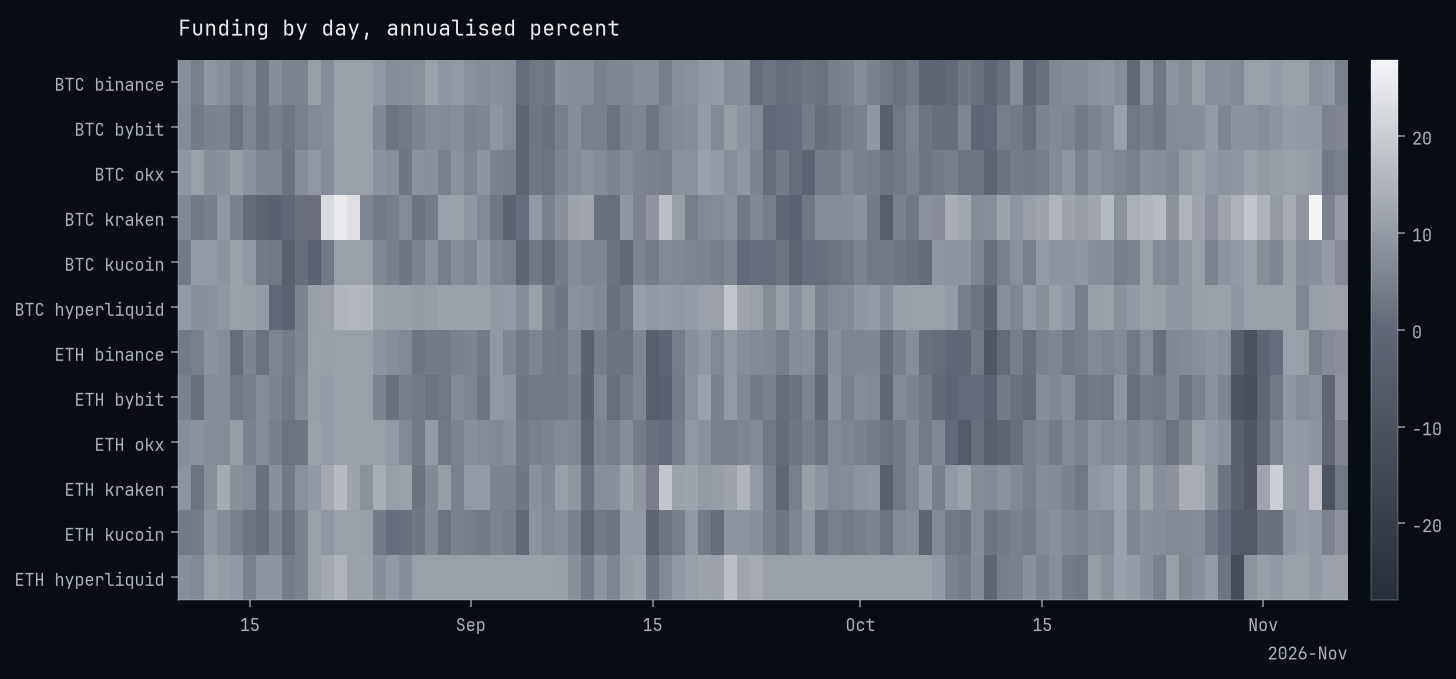

In [4]:
daily = pandas.DataFrame({key: frame["funding_per_hour"].resample(rule="1D").mean()
                          * 24 * 365 * 100
                          for key, frame in events.items()}).T

figure, axes = matplotlib.pyplot.subplots(figsize=(10.0, 4.6))

ink = matplotlib.colors.LinearSegmentedColormap.from_list(
    name="ink", colors=["#262e38", "#5f6874", "#f4f5f7"])
shown = axes.pcolormesh(daily.columns, range(len(daily)), daily.values, cmap=ink,
                        norm=matplotlib.colors.CenteredNorm(vcenter=0.0), shading="nearest")

axes.set_yticks(ticks=range(len(daily)), labels=[f"{coin} {exchange}"
                                                 for coin, exchange in daily.index])
axes.invert_yaxis()
axes.grid(visible=False)
axes.set_title(label="Funding by day, annualised percent")

figure.colorbar(mappable=shown, ax=axes, fraction=0.03, pad=0.02)
matplotlib.pyplot.show()

### The spread of the days

In [5]:
daily.T.describe(percentiles=[0.05, 0.5, 0.95]).T.drop(columns="count").round(decimals=1)

mean  std   min   5%   50%   95%   max
BTC binance       6.2  3.3  -1.2  0.3   7.1  11.0  11.0
    bybit         5.3  3.0  -3.1  0.4   5.4  10.2  11.0
    okx           6.3  3.1  -1.5  1.5   6.5  11.0  11.0
    kraken        8.2  6.1  -4.7 -1.0   8.1  17.8  27.9
    kucoin        5.6  3.4  -3.2  0.3   5.8  11.0  11.0
    hyperliquid   9.1  3.3  -2.1  2.5  10.1  11.6  18.2
ETH binance       4.8  3.9 -10.2 -1.8   5.7  10.8  11.0
    bybit         4.3  4.0 -10.9 -2.5   4.3  10.3  11.0
    okx           5.2  3.7  -7.9 -0.7   5.6  10.7  11.0
    kraken        7.9  4.9  -9.2  0.7   8.3  14.4  20.4
    kucoin        5.1  3.4  -6.4  0.2   5.2  10.5  11.0
    hyperliquid   8.8  3.8 -12.9  3.5  10.3  11.9  17.0

### What a position paid

`funding_paid` charges a discrete event at its time and a continuous sample over the part
of its window a position held, so one call serves every venue: a long of a million dollars
held through the window, each venue's events read as they came.

In [6]:
opened = int(start.timestamp() * 1_000)
closed = int(end.timestamp() * 1_000)

paid = pandas.Series({key: exchange_router.funding.funding_paid(frame, t_open=opened,
                                                                t_close=closed,
                                                                notional=1_000_000.0)
                      for key, frame in events.items()})

paid.unstack(level=0).reindex(index=list(SYMBOLS["BTC"])).round().astype(int)

,BTC,ETH
binance,15186,11796
bybit,13068,10549
okx,15626,12858
kraken,20285,19418
kucoin,13844,12637
hyperliquid,22509,21792
